In [1]:
import pandas as pd
import re
import os
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

### Analysis dependant global variables

In [10]:
# pep_folder = "NLFR_analysis"
# wt_seq = "NLFRRVWEL"
# pep_short = "NLFR"
# pep_file = "TCRneo_duplex_fingerprint_data_WT_TCR.tsv"
# HLA_allele = "HLA-B*08:01"

# pep_folder = "EVDP_analysis"
# wt_seq = "EVDPIGHLY"
# pep_short = "EVDP"
# pep_file = "TCRA3_duplex_fingerprint_data_WT_TCR.tsv"
# HLA_allele = "HLA-A*01:01"

pep_folder = "SLLQ_analysis"
wt_seq = "SLLQHLIGL"
pep_short = "SLLQ"
pep_file = "PRAMEb_duplex_fingerprint_data_WT_TCR.tsv"
HLA_allele = "HLA-A*02:01"



### Functions

In [4]:
def get_top1_model(df, metrics):
    grouped = df.groupby('pdb_id') # group by peptide
    results = []
    for pdb_id, group in grouped:
        res = {'pdb_id': pdb_id}
        for col in metrics:
            idx_max = group[col].idxmax()
            row = group.loc[idx_max]
            res[f'max_{col}'] = row[col]
            # values of all metrics at that same row
            for m in metrics:
                if m != col:
                    res[f'{m}_at_max_{col}'] = row[m]

        results.append(res)

    # Combine results into a DataFrame
    df_aggregated = pd.DataFrame(results)
    return df_aggregated

def pool_asymetric_chains(df):
    df_process = df.copy()
    chains = ['TRA', 'TRB', 'MHCA', 'pep']
    pairs_found = {}
    pae_cols = [c for c in df.columns if "pae" in c]
    ipsae_cols = [c for c in df.columns if "ipsae" in c]
    pdockq_cols = [c for c in df.columns if "pdockq" in c]
    process_cols = pae_cols + ipsae_cols + pdockq_cols

    for col in process_cols:
        for c1 in chains:
            for c2 in chains:
                if c1 == c2:
                    continue
                prefix_fwd = f"{c1}_{c2}_"
                prefix_rev = f"{c2}_{c1}_"
                if col.startswith(prefix_fwd):
                    suffix = col[len(prefix_fwd):]
                    reverse_metric = f"{prefix_rev}{suffix}"

                    if reverse_metric in process_cols:
                        # Canonical key: always sort chain names alphabetically
                        key = tuple(sorted([c1, c2])) + (suffix,)
                        if key not in pairs_found:
                            pairs_found[key] = {
                                'metric_1': col,
                                'metric_2': reverse_metric,
                                'suffix': suffix,
                                'chains': (c1, c2)
                            }
    
    cols_to_drop = []
    
    for key, info in pairs_found.items():
        c1, c2 = sorted(info['chains'])
        suffix = info['suffix']
        sym_name = f"{c1}_{c2}_{suffix}_sym"
        
        m1, m2 = info['metric_1'], info['metric_2']
        
        # Add symmetric column in place
        df_process[sym_name] = df_process[[m1, m2]].max(axis=1)
        
        # Mark originals for dropping
        cols_to_drop.extend([m1, m2])
            
    # Drop all asymmetric originals at once
    cols_to_drop = list(set(cols_to_drop))  # deduplicate
    df_process.drop(columns=cols_to_drop, inplace=True)
    
    return df_process

def add_tra_trb_max(df):
    """
    Adds max(TRA, TRB) columns for both naming styles:
    Keeps all original columns untouched.
    """
    new_cols = {}
    matched = set()

    for col in df.columns:
        if col == "contact_peptide_TCR":
            continue

        m = re.match(r"^TRA_(.+)$", col)
        if m:
            suffix = m.group(1)
            pair_col = f"TRB_{suffix}"
            pair_key = tuple(sorted([col, pair_col]))
            if pair_col in df.columns and pair_key not in matched:
                #new_name_min = f"TCR_{suffix}_min"
                new_name_max = f"TCR_{suffix}_max"
                #new_cols[new_name_min] = df[[col, pair_col]].min(axis=1)
                new_cols[new_name_max] = df[[col, pair_col]].max(axis=1)
                matched.add(pair_key)
            continue

        # Pattern 2: infix style — x_TRA_metric / x_TRB_metric
        m = re.match(r"^(.+)_TRA(_.+)$", col)
        if m:
            prefix, suffix = m.group(1), m.group(2)
            pair_col = f"{prefix}_TRB{suffix}"
            pair_key = tuple(sorted([col, pair_col]))
            if pair_col in df.columns and pair_key not in matched:
                #new_name_min = f"{prefix}_TCR{suffix}_min"
                new_name_max = f"{prefix}_TCR{suffix}_max"
                #new_cols[new_name_min] = df[[col, pair_col]].min(axis=1)
                new_cols[new_name_max] = df[[col, pair_col]].max(axis=1)
                matched.add(pair_key)

    return pd.concat([df, pd.DataFrame(new_cols, index=df.index)], axis=1)

def apply_mask_nocontact(df, mask):
    #Set to zero every entry in every column of df where the corresponding entry in mask is False
    df_masked = df.copy()
    for col in df_masked.columns:
        if col == "pdb_id" or col == "peptide" or col == "binder" or col == "batch" or col == "contact_peptide_TCR" or col =="sample_name":
            continue
        df_masked[col] = df_masked[col].where(mask, 0)
    return df_masked


def process_columns(df):
    df = df.copy()
    #df["mean_plddt"] = df["mean_plddt"] / 100.0

    pae_cols = [
        col for col in df.columns
        if (("pae" in col) or ("cdr_metric" in col)) and "fract_lt_10" not in col
    ]

    SCALE = 10  # PAE of 10Å gives score of 0.5 UNDERSTAND BETTER
    for col in pae_cols:
        #mask = df[col] == 100
        # df[col] = pd.to_numeric(df[col], errors='coerce')
        df[col] = 1 / (1 + df[col] / SCALE)
        #df.loc[mask, col] = 0

    #cols_plddt_interface = [col for col in df.columns if "plddt_perinterface" in col]
    #for col in cols_plddt_interface:
    #    mask = df[col] == -100
    #    df.loc[mask, col] = 0

    df = df.copy()
    
    
    df_sym = pool_asymetric_chains(df)
    df_combined = add_tra_trb_max(df_sym)
    mask_no_contact_TCRA = df_combined["TRA_pep_is_interface"] == 0
    mask_no_contact_TCRB = df_combined["TRB_pep_is_interface"] == 0
    df_combined["contact_peptide_TCR"] = ~ (mask_no_contact_TCRA | mask_no_contact_TCRB)
    df_masked = apply_mask_nocontact(df_combined, df_combined["contact_peptide_TCR"])
   
    df_combined["cdr_metric_general_max"] = (df_combined["pep_TCR_cdr_metric_mean_chain_max"] + df_combined["MHCA_TCR_cdr_metric_mean_chain_max"])/2
    df_combined["cdr_metric_general_weighted_max"] = (3*df_combined["pep_TCR_cdr_metric_mean_chain_max"] + 2*df_combined["MHCA_TCR_cdr_metric_mean_chain_max"])/5
    
    df_masked["cdr_metric_general_max"] = (df_masked["pep_TCR_cdr_metric_mean_chain_max"] + df_masked["MHCA_TCR_cdr_metric_mean_chain_max"])/2
    df_masked["cdr_metric_general_weighted_max"] = (3*df_masked["pep_TCR_cdr_metric_mean_chain_max"] + 2*df_masked["MHCA_TCR_cdr_metric_mean_chain_max"])/5
    return df_combined, df_masked


def clean_duplicate_metrics(df):
    cols_to_keep = []
    seen = set()

    for col in df.columns:
        parts = col.split('_')
        pair = sorted(parts[:2])
        canonical = '_'.join(pair + parts[2:])
        if canonical not in seen:
            seen.add(canonical)
            cols_to_keep.append(col)

    return cols_to_keep

## Structure selection on AF3 output

In [11]:
# df_results = pd.read_csv("../data/af3_output_base3/allresults_af3_base3.csv")
# df_results = df_results.rename(
    # {"name": "pdb_id"}, axis=1)

df_expanded_swapped = pd.read_csv(f"../results/{pep_folder}/af3_output/structInference_{pep_short}/allresults_merged_expanded.csv")
df_proc_raw, df_masked = process_columns(df_expanded_swapped)
all_na_cols = df_masked.columns[df_masked.isna().all()]
df_masked.drop(columns=all_na_cols, inplace=True)
cols_to_keep = clean_duplicate_metrics(df_masked)
df_masked_proc = df_masked[cols_to_keep].copy()
pae_min_chain_cols = [c for c in df_masked_proc.columns if "min_pae_chain" in c]
df_masked_proc.drop(columns=pae_min_chain_cols, inplace=True)
# df_all_masked = df_masked_proc.merge(df_results, on="pdb_id")
df_all_masked = df_masked_proc.copy()

patterns_remove = ["p20_pae",
                 "perinterface",
                 #"TRA",
                 #"TRB",
                  "fract_lt_10_",
                  "mean_pae_chain"]

cols_remove = [c for c in df_all_masked.columns if any(re.search(pattern, c) for pattern in patterns_remove)]
df_all_masked.drop(columns=cols_remove, inplace=True)

ipsae = [c for c in df_all_masked.columns if "ipsae" in c]
other_cols = ['af_confidence']  # can expand if needed
#model_score_cols = [c for c in df_all.columns if "model_score" in c]
metrics = other_cols + ipsae

df_aggregated_masked = get_top1_model(df_all_masked, metrics)
# score_df_masked = df_aggregated_masked.merge(df_results, on="pdb_id")
score_df_masked = df_aggregated_masked.copy()

### Collecting and extracting the seed_sample of the structures selected on a specific metric

In [ ]:
metric_name = "TCR_pep_ipsae_d0dom_sym_max"  # Selected metric, but in the df_all_masked object

best_indices = df_all_masked.groupby(df_expanded_swapped["pdb_id"])[metric_name].idxmax()

df_selected_models = pd.DataFrame({
    "pdb_id": df_expanded_swapped.loc[best_indices, "pdb_id"].values,
    "seed_sample": df_expanded_swapped.loc[best_indices, "sample_name"].values,
    "max_score": df_all_masked.loc[best_indices, metric_name].values
})

os.makedirs(f"../data/{pep_folder}/af3_output_base3", exist_ok=True)
df_selected_models.head()
df_selected_models.to_csv(f"../data/{pep_folder}/af3_output_base3/selected_structures.csv", index=False)

## Exporting ipSAE score for all WT structures predicted 
This metadata is needed to assess WT diversity with the docking analysis

In [12]:
metric_name = "TCR_pep_ipsae_d0dom_sym_max"  # Selected metric, but in the df_all_masked object
wt_mask = df_expanded_swapped["pdb_id"] == f"{pep_short}-P0_WT"

df_WT_ipsae = pd.DataFrame({
    "seed_sample": df_expanded_swapped.loc[wt_mask, "sample_name"].values,
    "ipsae_score": df_all_masked.loc[wt_mask, metric_name].values
})

os.makedirs(f"../data/{pep_folder}/af3_output_base3", exist_ok=True)

df_WT_ipsae.to_csv(f"../data/{pep_folder}/af3_output_base3/WT_ipsae_scores.csv", index=False)

## Focusing on the fraction of rejected structures (interface criterium)

In [17]:
# Use df_proc_raw containing all models prior to NaN mask filtering
if "contact_peptide_TCR" not in df_proc_raw.columns:
  df_proc_raw["contact_peptide_TCR"] = (
      df_proc_raw["TRA_pep_is_interface"] == 1
  ) & (df_proc_raw["TRB_pep_is_interface"] == 1)

# Binary indicator: 1 if model lacked interface contacts, 0 otherwise
df_proc_raw["is_discarded"] = (~df_proc_raw["contact_peptide_TCR"]).astype(int)

# Parse mutation position and residue if not already present
if "Peptide_pos" not in df_proc_raw.columns:
  df_proc_raw["Peptide_pos"] = (
      df_proc_raw["pdb_id"].str.extract(r"P(\d+)_")[0].astype(float)
  )
  df_proc_raw["Peptide_res"] = df_proc_raw["pdb_id"].str.extract(r"P\d+_([A-Z])")[
      0
  ]


# Now we compute the statistics across every mutant (and gather them by residue)
total_models = len(df_proc_raw)
discarded_models = int(df_proc_raw["is_discarded"].sum())
pct_discarded = (discarded_models / total_models) * 100

print(
    f"Total models evaluated: {total_models} | Discarded (no contact):"
    f" {discarded_models} ({pct_discarded:.2f}%)"
)

# Aggregated failure rate per peptide mutant (across seeds)
df_discard_per_mutant = (
    df_proc_raw.groupby(["Peptide_pos", "Peptide_res"])["is_discarded"]
    .agg(n_models="count", n_discarded="sum", discard_rate="mean")
    .reset_index()
)

# Identify variants where 100% of modeled seeds failed interface criteria
complete_failures = df_discard_per_mutant[
    df_discard_per_mutant["discard_rate"] == 1.0
]
print(
    f"\nNumber of mutants with zero valid interface models:"
    f" {len(complete_failures)} / {len(df_discard_per_mutant)}"
)
if not complete_failures.empty:
  print(
      complete_failures[["Peptide_pos", "Peptide_res", "n_discarded"]].to_string(
          index=False
      )
  )

# Mean discard rate per peptide position (P1 -> P9)
df_discard_per_pos = (
    df_proc_raw[df_proc_raw["Peptide_pos"] > 0]
    .groupby("Peptide_pos")["is_discarded"]
    .mean()
    * 100
)

Total models evaluated: 8600 | Discarded (no contact): 20 (0.23%)

Number of mutants with zero valid interface models: 0 / 172


### Visualization (if ever needed)

In [9]:
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# # Panel 1: Barplot of discarded models percentage per position
# df_discard_per_pos.plot(
#     kind="bar", ax=ax1, color="#4A7BB7", edgecolor="black", width=0.7
# )
# ax1.set_title(f"Fraction of Discarded AF3 Models per Position ({pep_short})")
# ax1.set_xlabel("Peptide Position")
# ax1.set_ylabel("% Models Without Interface Contact")
# ax1.set_ylim(0, 100)
# ax1.grid(axis="y", linestyle="--", alpha=0.6)

# # Panel 2: Heatmap showing discard fraction across all amino acid substitutions
# matrix_discard = df_discard_per_mutant.pivot(
#     index="Peptide_res", columns="Peptide_pos", values="discard_rate"
# ).sort_index()

# sns.heatmap(
#     matrix_discard,
#     cmap="YlOrRd",
#     vmin=0,
#     vmax=1,
#     cbar_kws={"label": "Fraction of Discarded Seeds (No Interface)"},
#     ax=ax2,
# )
# ax2.set_title(f"Discarded AF3 Models Heatmap ({pep_short})")
# ax2.set_xlabel("Peptide Position")
# ax2.set_ylabel("Peptide Residue")

# plt.tight_layout()
# plt.show()

## Heatmap analysis with ipsae d0dom metric

In [10]:
alphabet_file = "../data/Matrices/alphabet"
alphabet = np.loadtxt("../data/Matrices/alphabet", dtype=str)

target_metric = "max_TCR_pep_ipsae_d0dom_sym_max"

matrix_tcr = pd.DataFrame(index=alphabet, columns=range(1, 10), dtype=float)
score_lookup = score_df_masked.set_index("pdb_id")[target_metric]

# Adding score to matrix
for pos, wt_aa in enumerate(wt_seq, start=1):
    for aa in alphabet:
        if aa == wt_aa:
            pdb_id = f"{pep_short}-P0_WT" 
        else:
            pdb_id = f"{pep_short}-P{pos}_{aa}"
        if pdb_id in score_lookup.index:
            matrix_tcr.loc[aa, pos] = score_lookup.loc[pdb_id]
        else:
            matrix_tcr.loc[aa, pos] = np.nan

# sorting the residues to obtain the same order as in the Baseline I
matrix_tcr = matrix_tcr.sort_index()


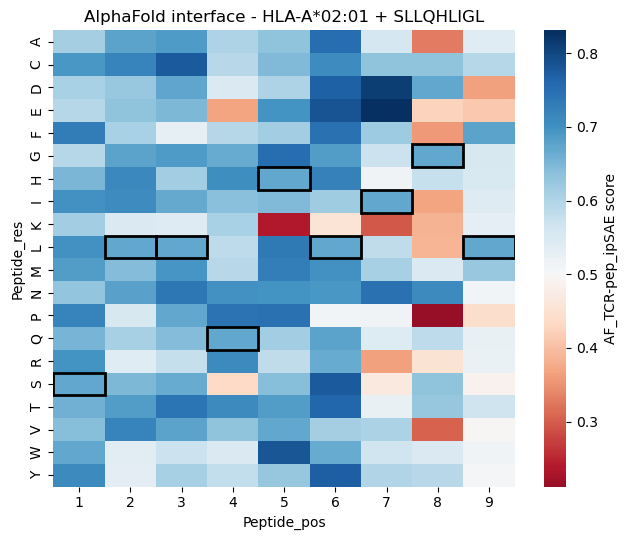

In [11]:
# Heatmap plot for the score matrix
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(
    matrix_tcr,
    cmap="RdBu",
    center=0.5,
    cbar_kws={"label": "AF_TCR-pep_ipSAE score"},
    ax=ax,
)

# Highlighting the WT sequence 
for pos, aa in enumerate(wt_seq, start=1):
    if aa in matrix_tcr.index and pos in matrix_tcr.columns:
        x = matrix_tcr.columns.get_loc(pos)
        y = matrix_tcr.index.get_loc(aa)
        ax.add_patch(
            patches.Rectangle(
                (x, y), 1, 1, fill=False, edgecolor="black", lw=2
            )
        )

# Crossing out the residues without data
for r_idx, aa in enumerate(matrix_tcr.index):
    for c_idx, pos in enumerate(matrix_tcr.columns):
        if pd.isna(matrix_tcr.loc[aa, pos]):
            ax.text(
                c_idx + 0.5,
                r_idx + 0.5,
                "X",
                ha="center",
                va="center",
                color="black",
                fontsize=11,
            )

ax.set_title(f"AlphaFold interface - {HLA_allele} + {wt_seq}")
ax.set_xlabel("Peptide_pos")
ax.set_ylabel("Peptide_res")
plt.tight_layout()
plt.show()

## Importing experimental data for correlation

In [14]:
df_orig = pd.read_csv(f"../data/{pep_folder}/{pep_file}", sep="\t")

df_mut_orig = df_orig[df_orig["Peptide_pos"] > 0]

# Pivot to obtain the experimental 20x9 matrix
matrix_exp = df_mut_orig.pivot(
    index="Peptide_res",
    columns="Peptide_pos",
    values="Peptide_log2_mean_umi_count"
).sort_index()

# Add back the WT reference score across all positions (same score over all WT peptide)
wt_val = df_orig.loc[df_orig["Peptide_pos"] == 0, "Peptide_log2_mean_umi_count"].values[0]

for pos, aa in enumerate(wt_seq, start=1):
    if aa in matrix_exp.index and pos in matrix_exp.columns:
        matrix_exp.loc[aa, pos] = wt_val


def compute_columnwise_pcc(df_ref, df_pred):
    records = []
    common_cols = [col for col in df_ref.columns if col in df_pred.columns]

    for pos in common_cols:
        combined = pd.concat([df_ref[pos].rename("ref"), df_pred[pos].rename("pred")], axis=1).dropna()
        
        x = combined["ref"].astype(float)
        y = combined["pred"].astype(float)

        # Pearson requires at least 3 points and non-zero standard deviation
        if len(x) >= 3 and x.std() > 1e-8 and y.std() > 1e-8:
            p_res = stats.pearsonr(x, y)
            s_res = stats.spearmanr(x, y)
            pcc, pcc_pval = p_res.statistic, p_res.pvalue
            scc, scc_pval = s_res.statistic, s_res.pvalue
        else:
            pcc, pcc_pval, scc, scc_pval = np.nan, np.nan, np.nan, np.nan

        records.append({
            "Peptide_pos": pos,
            "PCC": pcc,
            "p_value_pcc": pcc_pval,
            "SCC": scc,
            "p_value_scc": scc_pval,
            "n_points": len(x)
        })

    return pd.DataFrame(records)

pcc_tcr = compute_columnwise_pcc(matrix_exp, matrix_tcr)

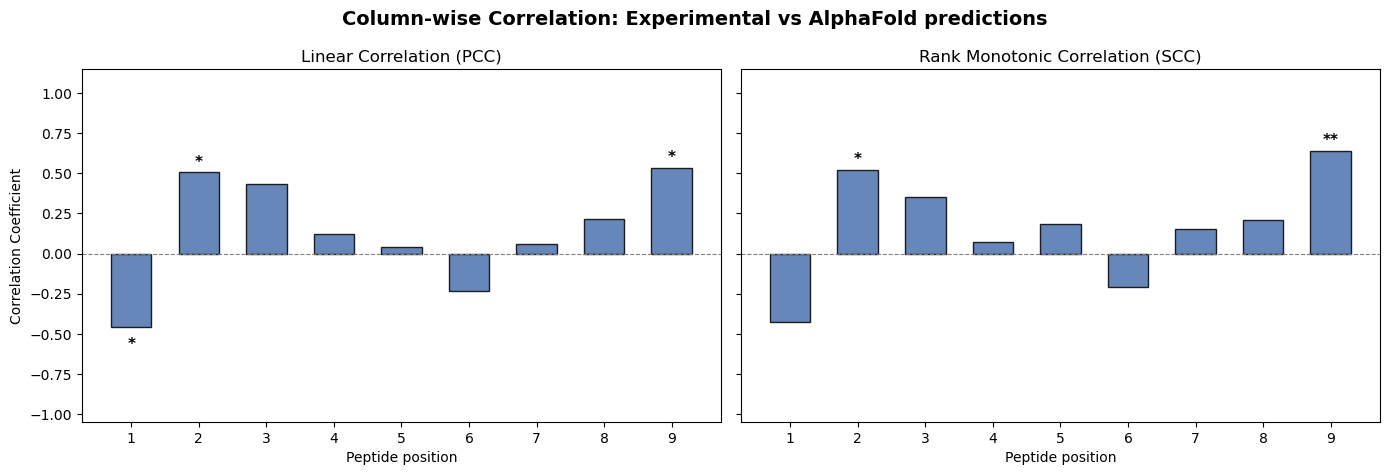

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)

# Helper function to format and annotate bars
def plot_bars(ax, df, metric_name, pval_col, title):
    bars = ax.bar(
        df["Peptide_pos"],
        df[metric_name],
        color="#4C72B0",
        edgecolor="black",
        width=0.6,
        alpha=0.85
    )

    # Add significance stars
    for idx, row in df.iterrows():
        val = row[metric_name]
        pval = row[pval_col]
        if not np.isnan(val):
            star = "***" if pval < 0.001 else ("**" if pval < 0.01 else ("*" if pval < 0.05 else ""))
            y_pos = val + (0.02 if val >= 0 else -0.06)
            ax.text(
                row["Peptide_pos"],
                y_pos,
                star,
                ha="center",
                va="bottom" if val >= 0 else "top",
                fontsize=11,
                fontweight="bold"
            )

    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_ylim(-1.05, 1.15)
    ax.set_xticks(range(1, 10))
    ax.set_xlabel("Peptide position")
    ax.set_title(title, fontsize=12)

plot_bars(
    ax1,
    pcc_tcr,
    metric_name="PCC",
    pval_col="p_value_pcc" if "p_value_pcc" in pcc_tcr.columns else "p_value",
    title="Linear Correlation (PCC)"
)
ax1.set_ylabel("Correlation Coefficient")

# Trace le deuxième graphique (SCC)
plot_bars(
    ax2,
    pcc_tcr,
    metric_name="SCC",
    pval_col="p_value_scc" if "p_value_scc" in pcc_tcr.columns else "p_value",
    title="Rank Monotonic Correlation (SCC)"
)

fig.suptitle("Column-wise Correlation: Experimental vs AlphaFold predictions", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()



## Exporting data matrix

In [46]:
matrix_tcr.to_csv(f"../results/{pep_folder}/heatmaps/matrix_af_interface.tsv", sep="\t")

## Exploring structure alignement

This part is to be ran after alignment of the structures in PyMol.

In [6]:
df_com = pd.read_csv(f"../results/{pep_folder}/cdr_CoM_169_af3.csv", index_col="model")
# df_com = pd.read_csv("../results/{pep_folder}/cdr_CoM_50WT_af3.csv", index_col="model")
df_mhc = pd.read_csv((f"../results/{pep_folder}/mhc_groove_backdrop.csv"))

cdr_definitions = {
    "CDR1_alpha": ("D", "resi 27-32"),
    "CDR2_alpha": ("D", "resi 50-56"),
    "CDR3_alpha": ("D", "resi 91-103"),
    "CDR1_beta":  ("E", "resi 27-31"),
    "CDR2_beta":  ("E", "resi 49-54"),
    "CDR3_beta":  ("E", "resi 92-103"),
}

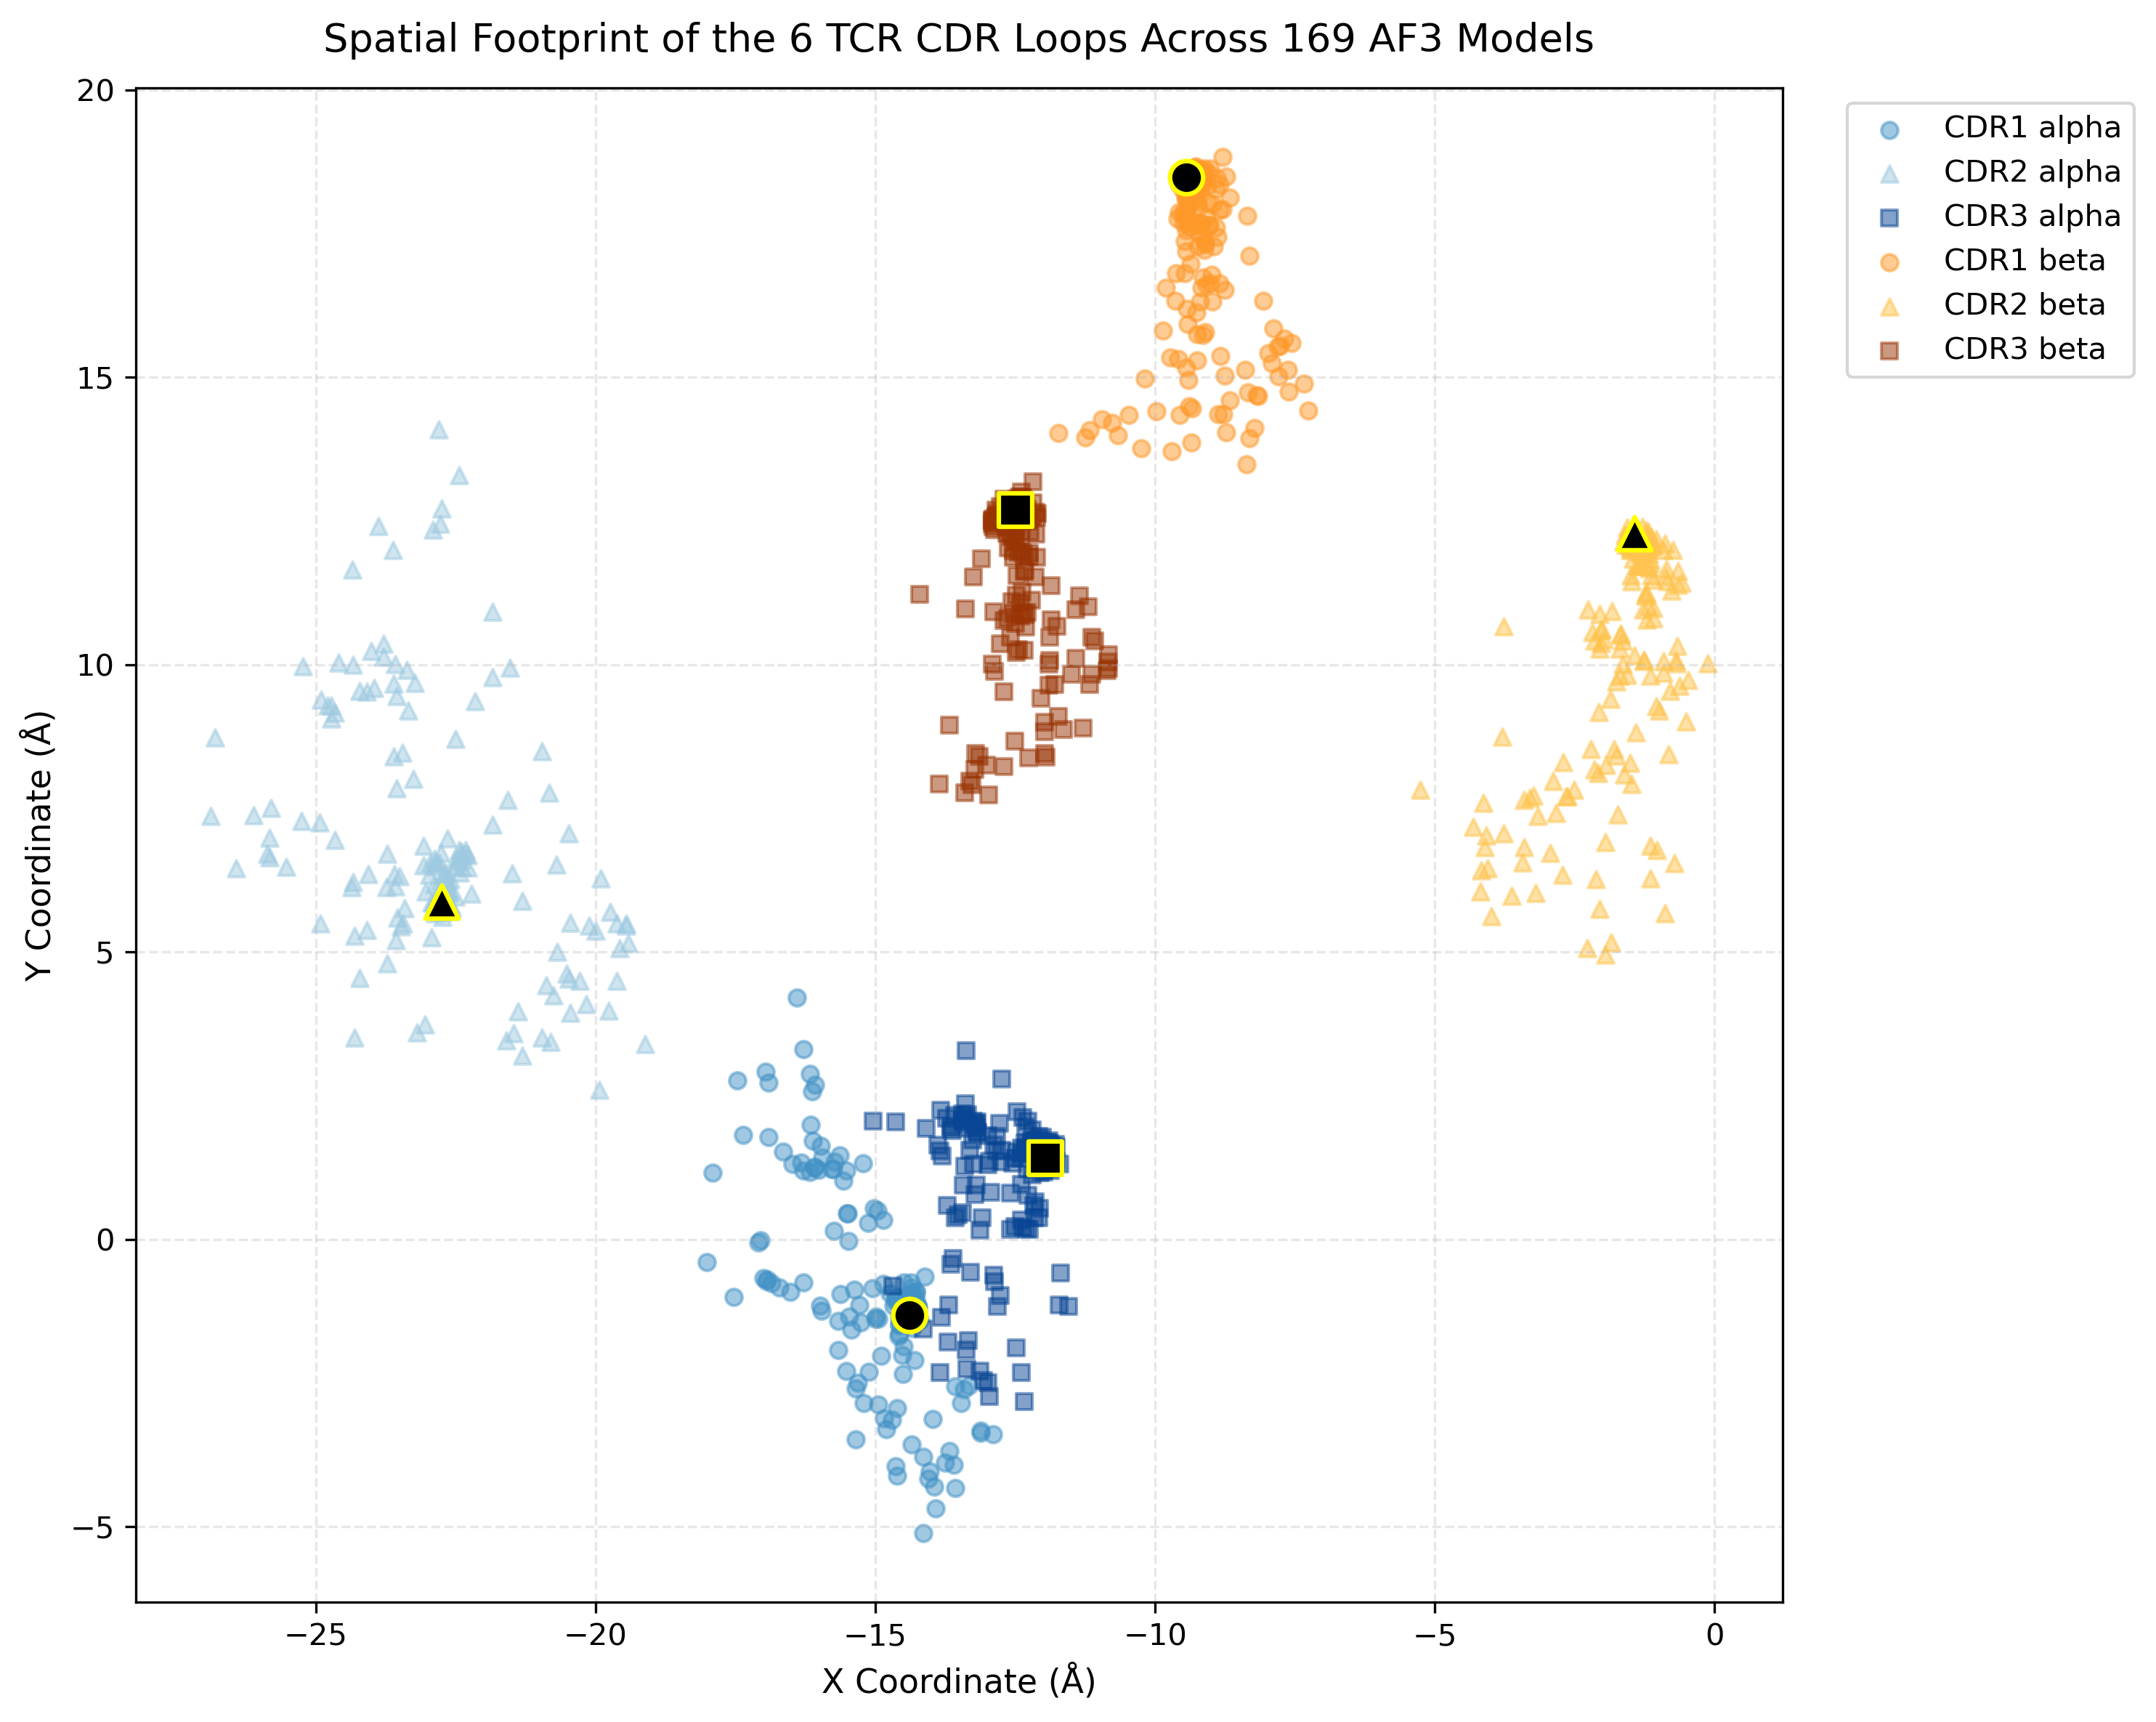

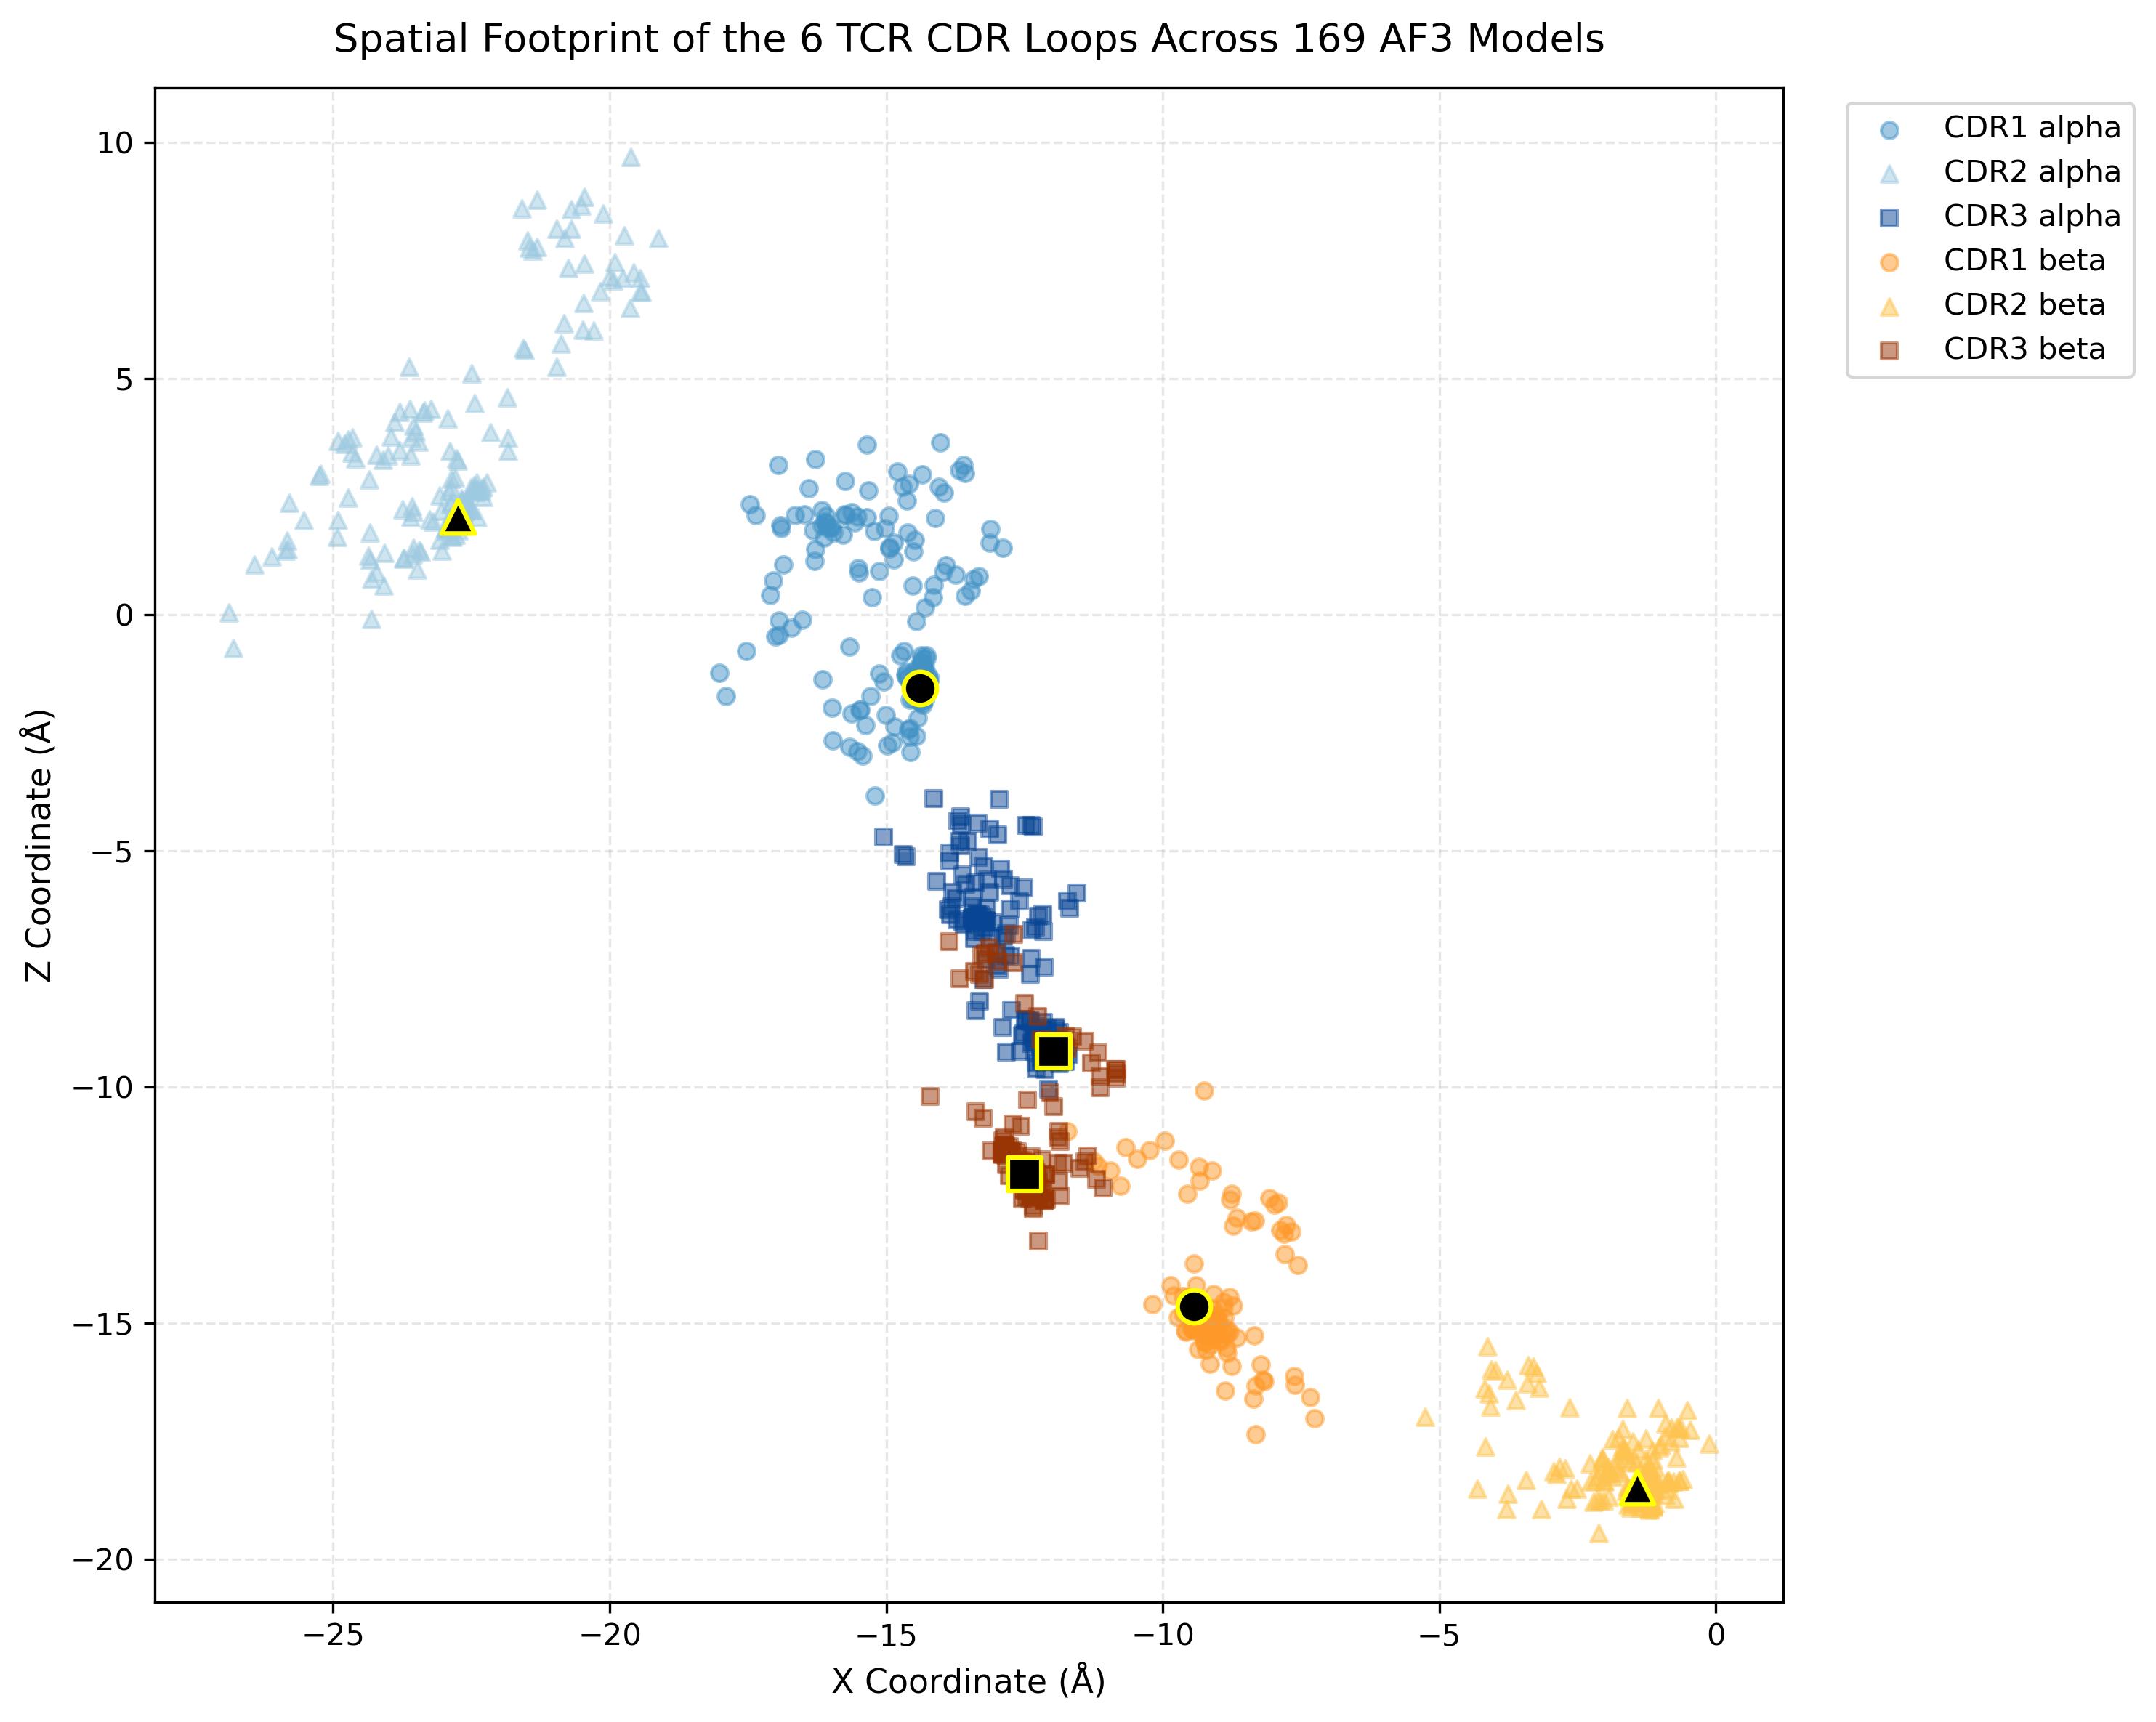

KeyboardInterrupt: 

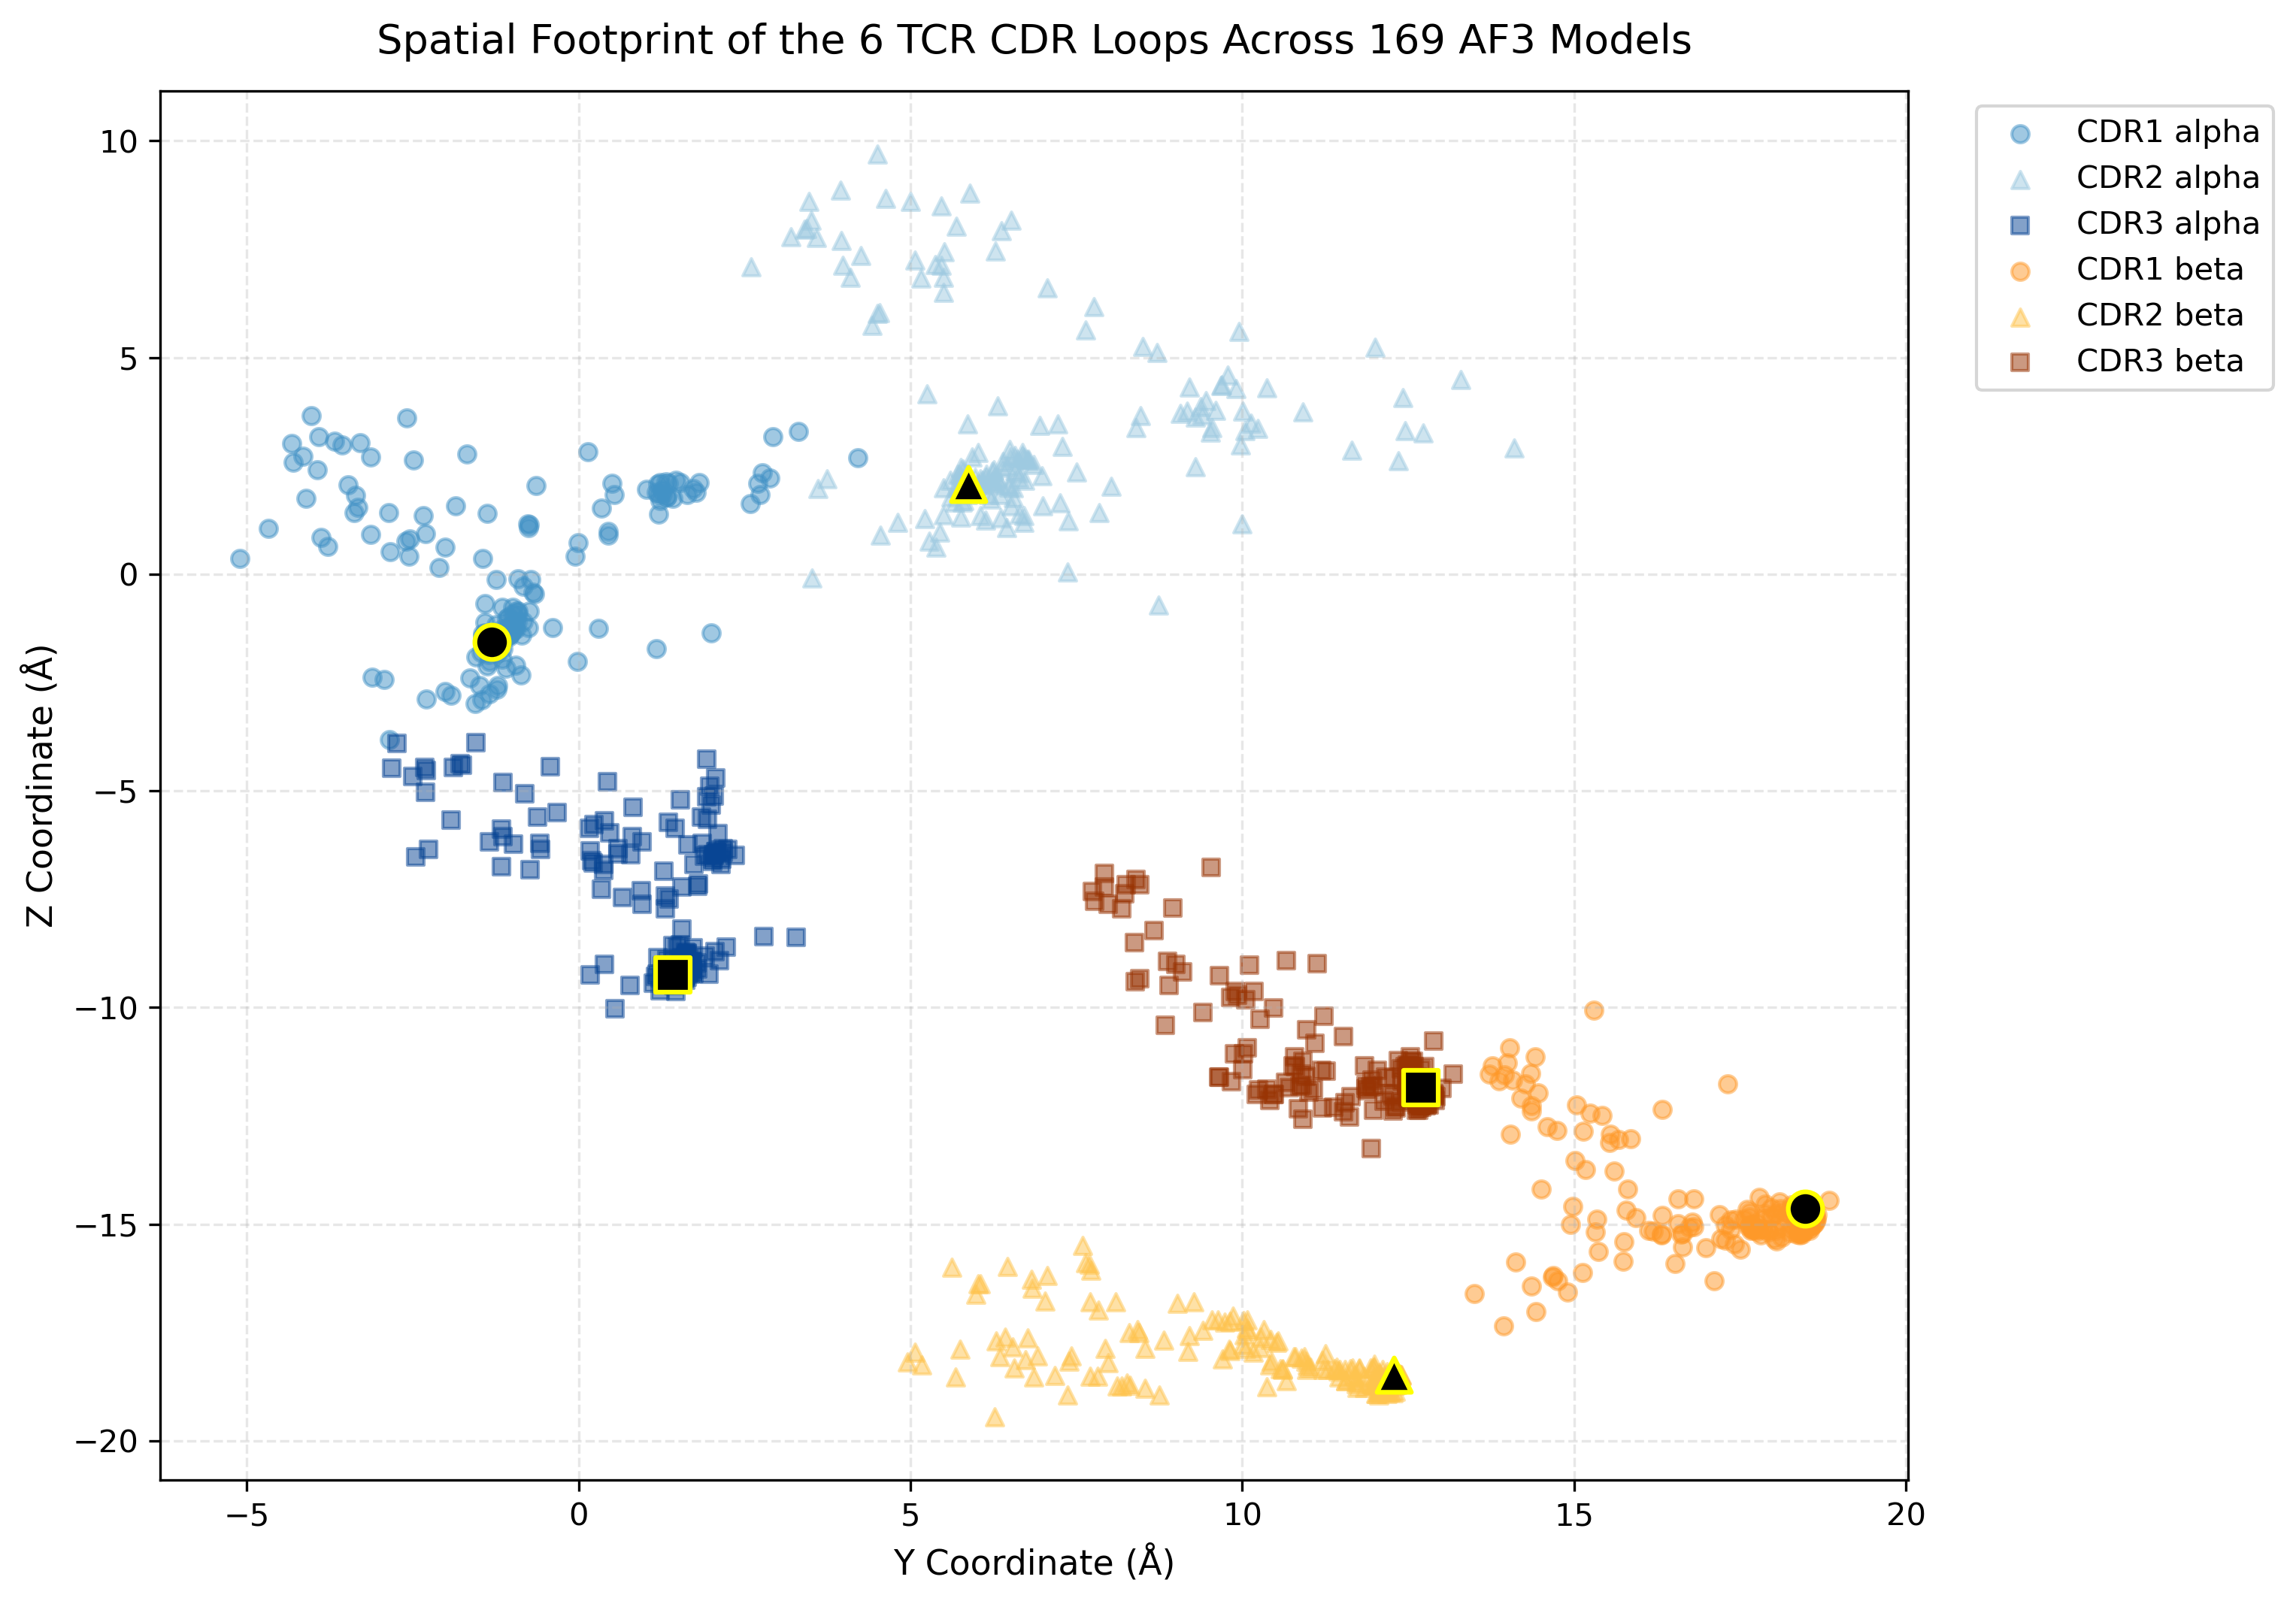

In [7]:


colors = {
    "CDR1_alpha": "#4292c6",  # light blue
    "CDR2_alpha": "#9ecae1",  # very light blue
    "CDR3_alpha": "#084594",  # dark navy blue
    "CDR1_beta":  "#fe9929",  # light orange
    "CDR2_beta":  "#fec44f",  # light gold
    "CDR3_beta":  "#993404",  # dark brown/red
}

markers = {
    "CDR1_alpha": "o", "CDR2_alpha": "^", "CDR3_alpha": "s",
    "CDR1_beta":  "o", "CDR2_beta":  "^", "CDR3_beta":  "s"
}

dims_list = [("x", "y"), ("x", "z"), ("y", "z")]
# Plot non-WT models (or non-selected if we only refer to the WT selection process)
mask_mut = ~df_com["is_wt"]
# mask_mut = ~df_com["is_selected"]

for (dim_1, dim_2) in dims_list:
    plt.figure(figsize=(10, 8), dpi=300)

    for cdr_name in cdr_definitions.keys():
        plt.scatter(
            df_com.loc[mask_mut, f"{cdr_name}_{dim_1}"].astype(float),
            df_com.loc[mask_mut, f"{cdr_name}_{dim_2}"].astype(float),
            color=colors[cdr_name],
            marker=markers[cdr_name],
            alpha=0.5,
            s=30,
            label=cdr_name.replace("_", " ")
        )

    # Highlight WT reference model
    mask_wt = df_com["is_wt"]
    # mask_wt = df_com["is_selected"]
    if mask_wt.any():
        for cdr_name in cdr_definitions.keys():
            plt.scatter(
                df_com.loc[mask_wt, f"{cdr_name}_{dim_1}"].astype(float),
                df_com.loc[mask_wt, f"{cdr_name}_{dim_2}"].astype(float),
                color="black",
                edgecolors="yellow",
                marker=markers[cdr_name],
                s=120,
                linewidth=1.5,
                zorder=5
            )

    plt.title("Spatial Footprint of the 6 TCR CDR Loops Across 169 AF3 Models", fontsize=13, pad=12)
    # plt.title("Spatial Footprint of the 6 TCR CDR Loops Across 50 WT AF3 Models", fontsize=13, pad=12)
    plt.xlabel(f"{dim_1.upper()} Coordinate (Å)", fontsize=11)
    plt.ylabel(f"{dim_2.upper()} Coordinate (Å)", fontsize=11)
    plt.legend(bbox_to_anchor=(1.03, 1), loc="upper left", frameon=True, fontsize=10)
    plt.grid(True, linestyle="--", alpha=0.3)
    plt.tight_layout()

    plot_out = f"../figures/{pep_folder}/tcr_6_cdr_footprint_scatterplot_{dim_1.upper()}{dim_2.upper()}.png"
    plt.savefig(plot_out)
    plt.show()
    plt.close()

### Adding the MHC and peptide drawn in the background

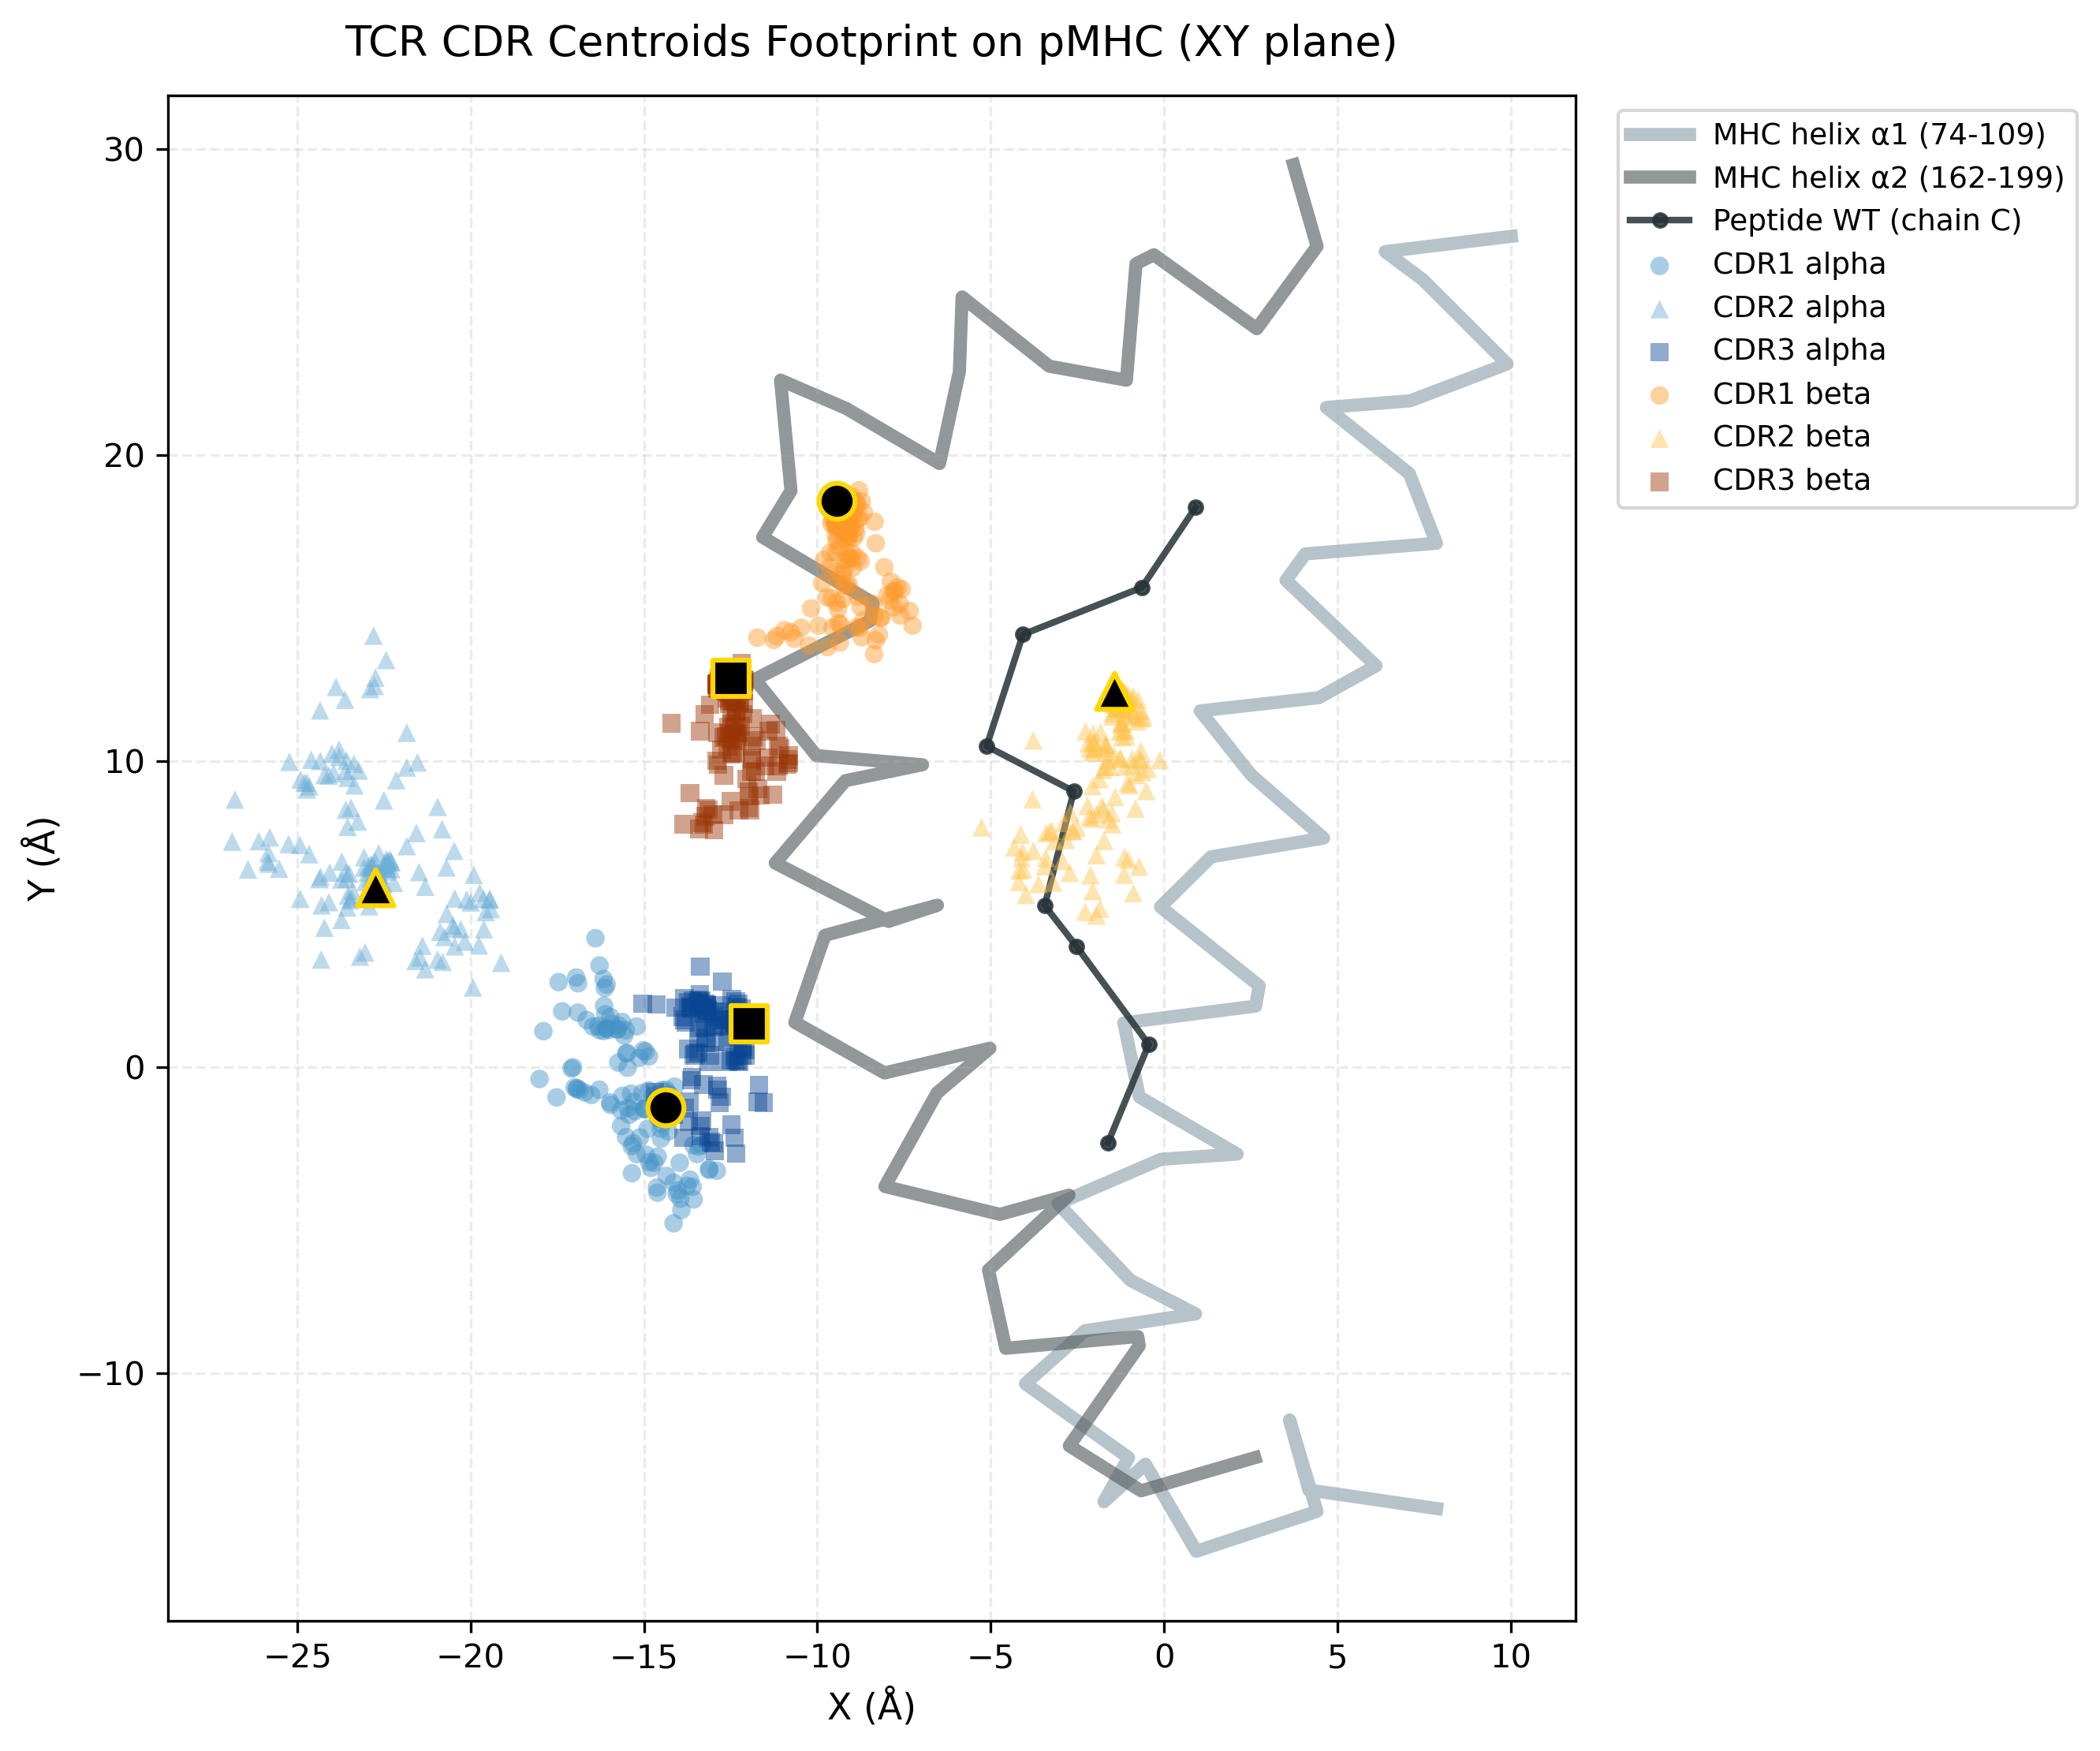

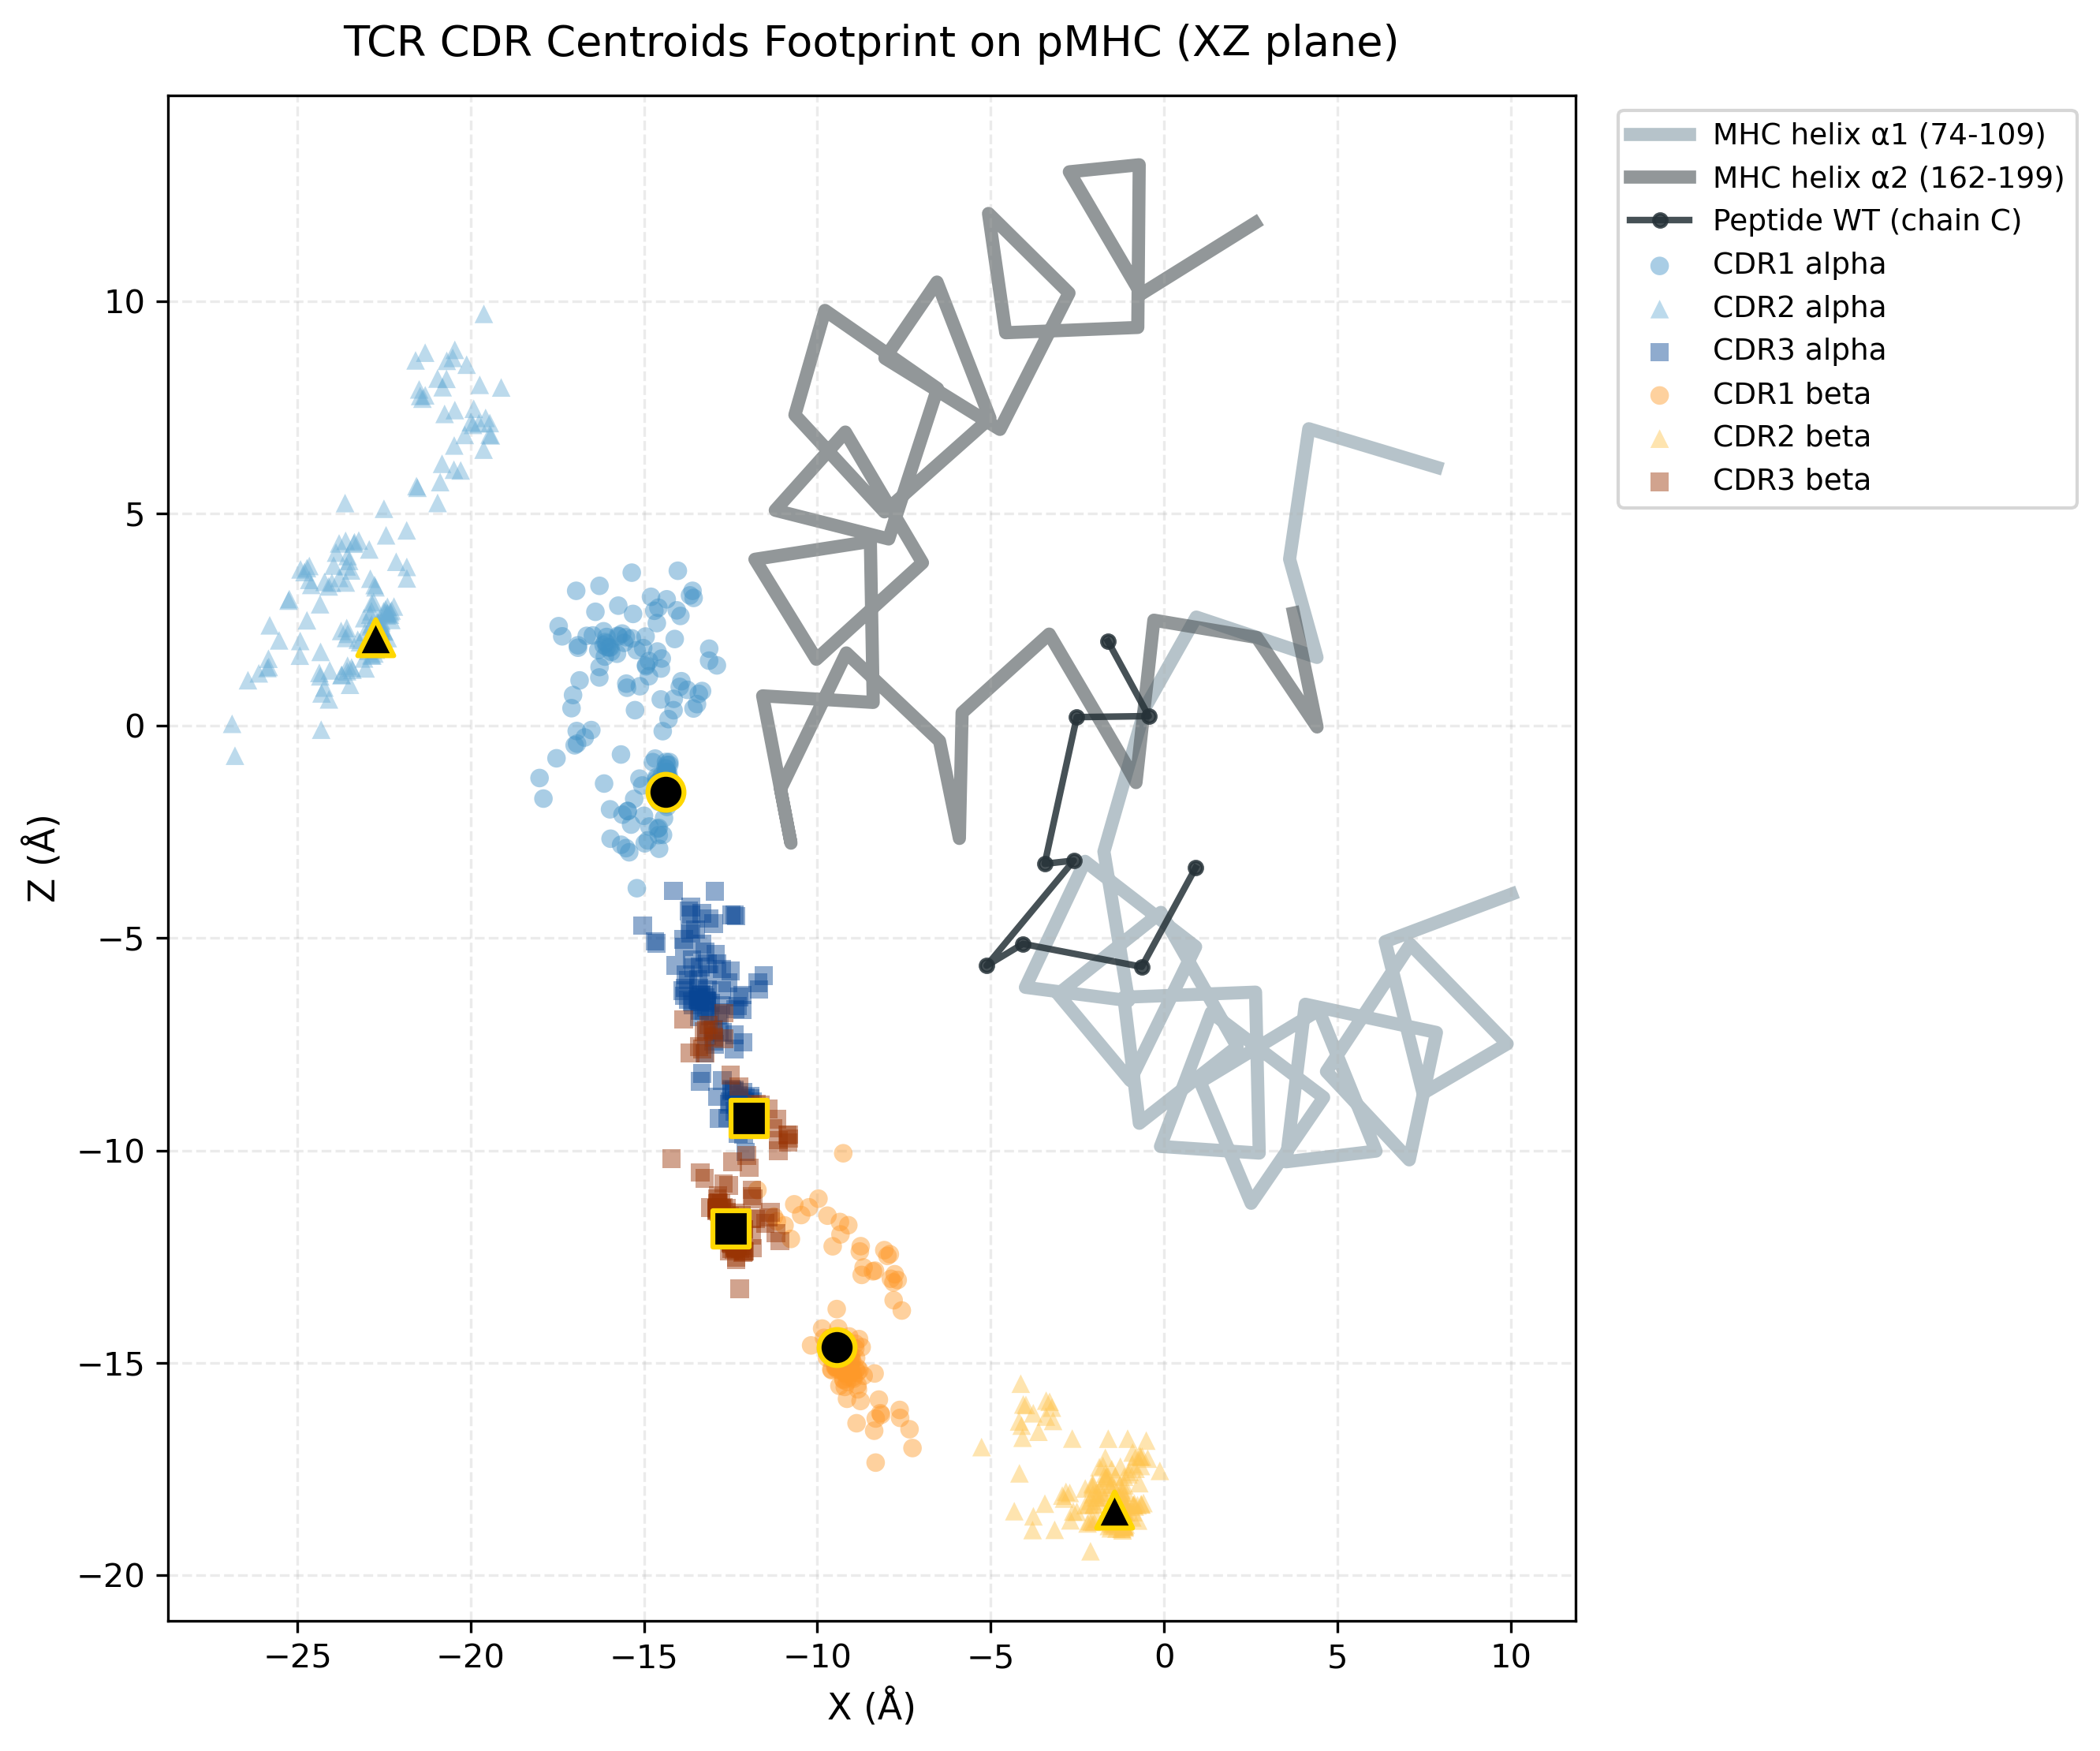

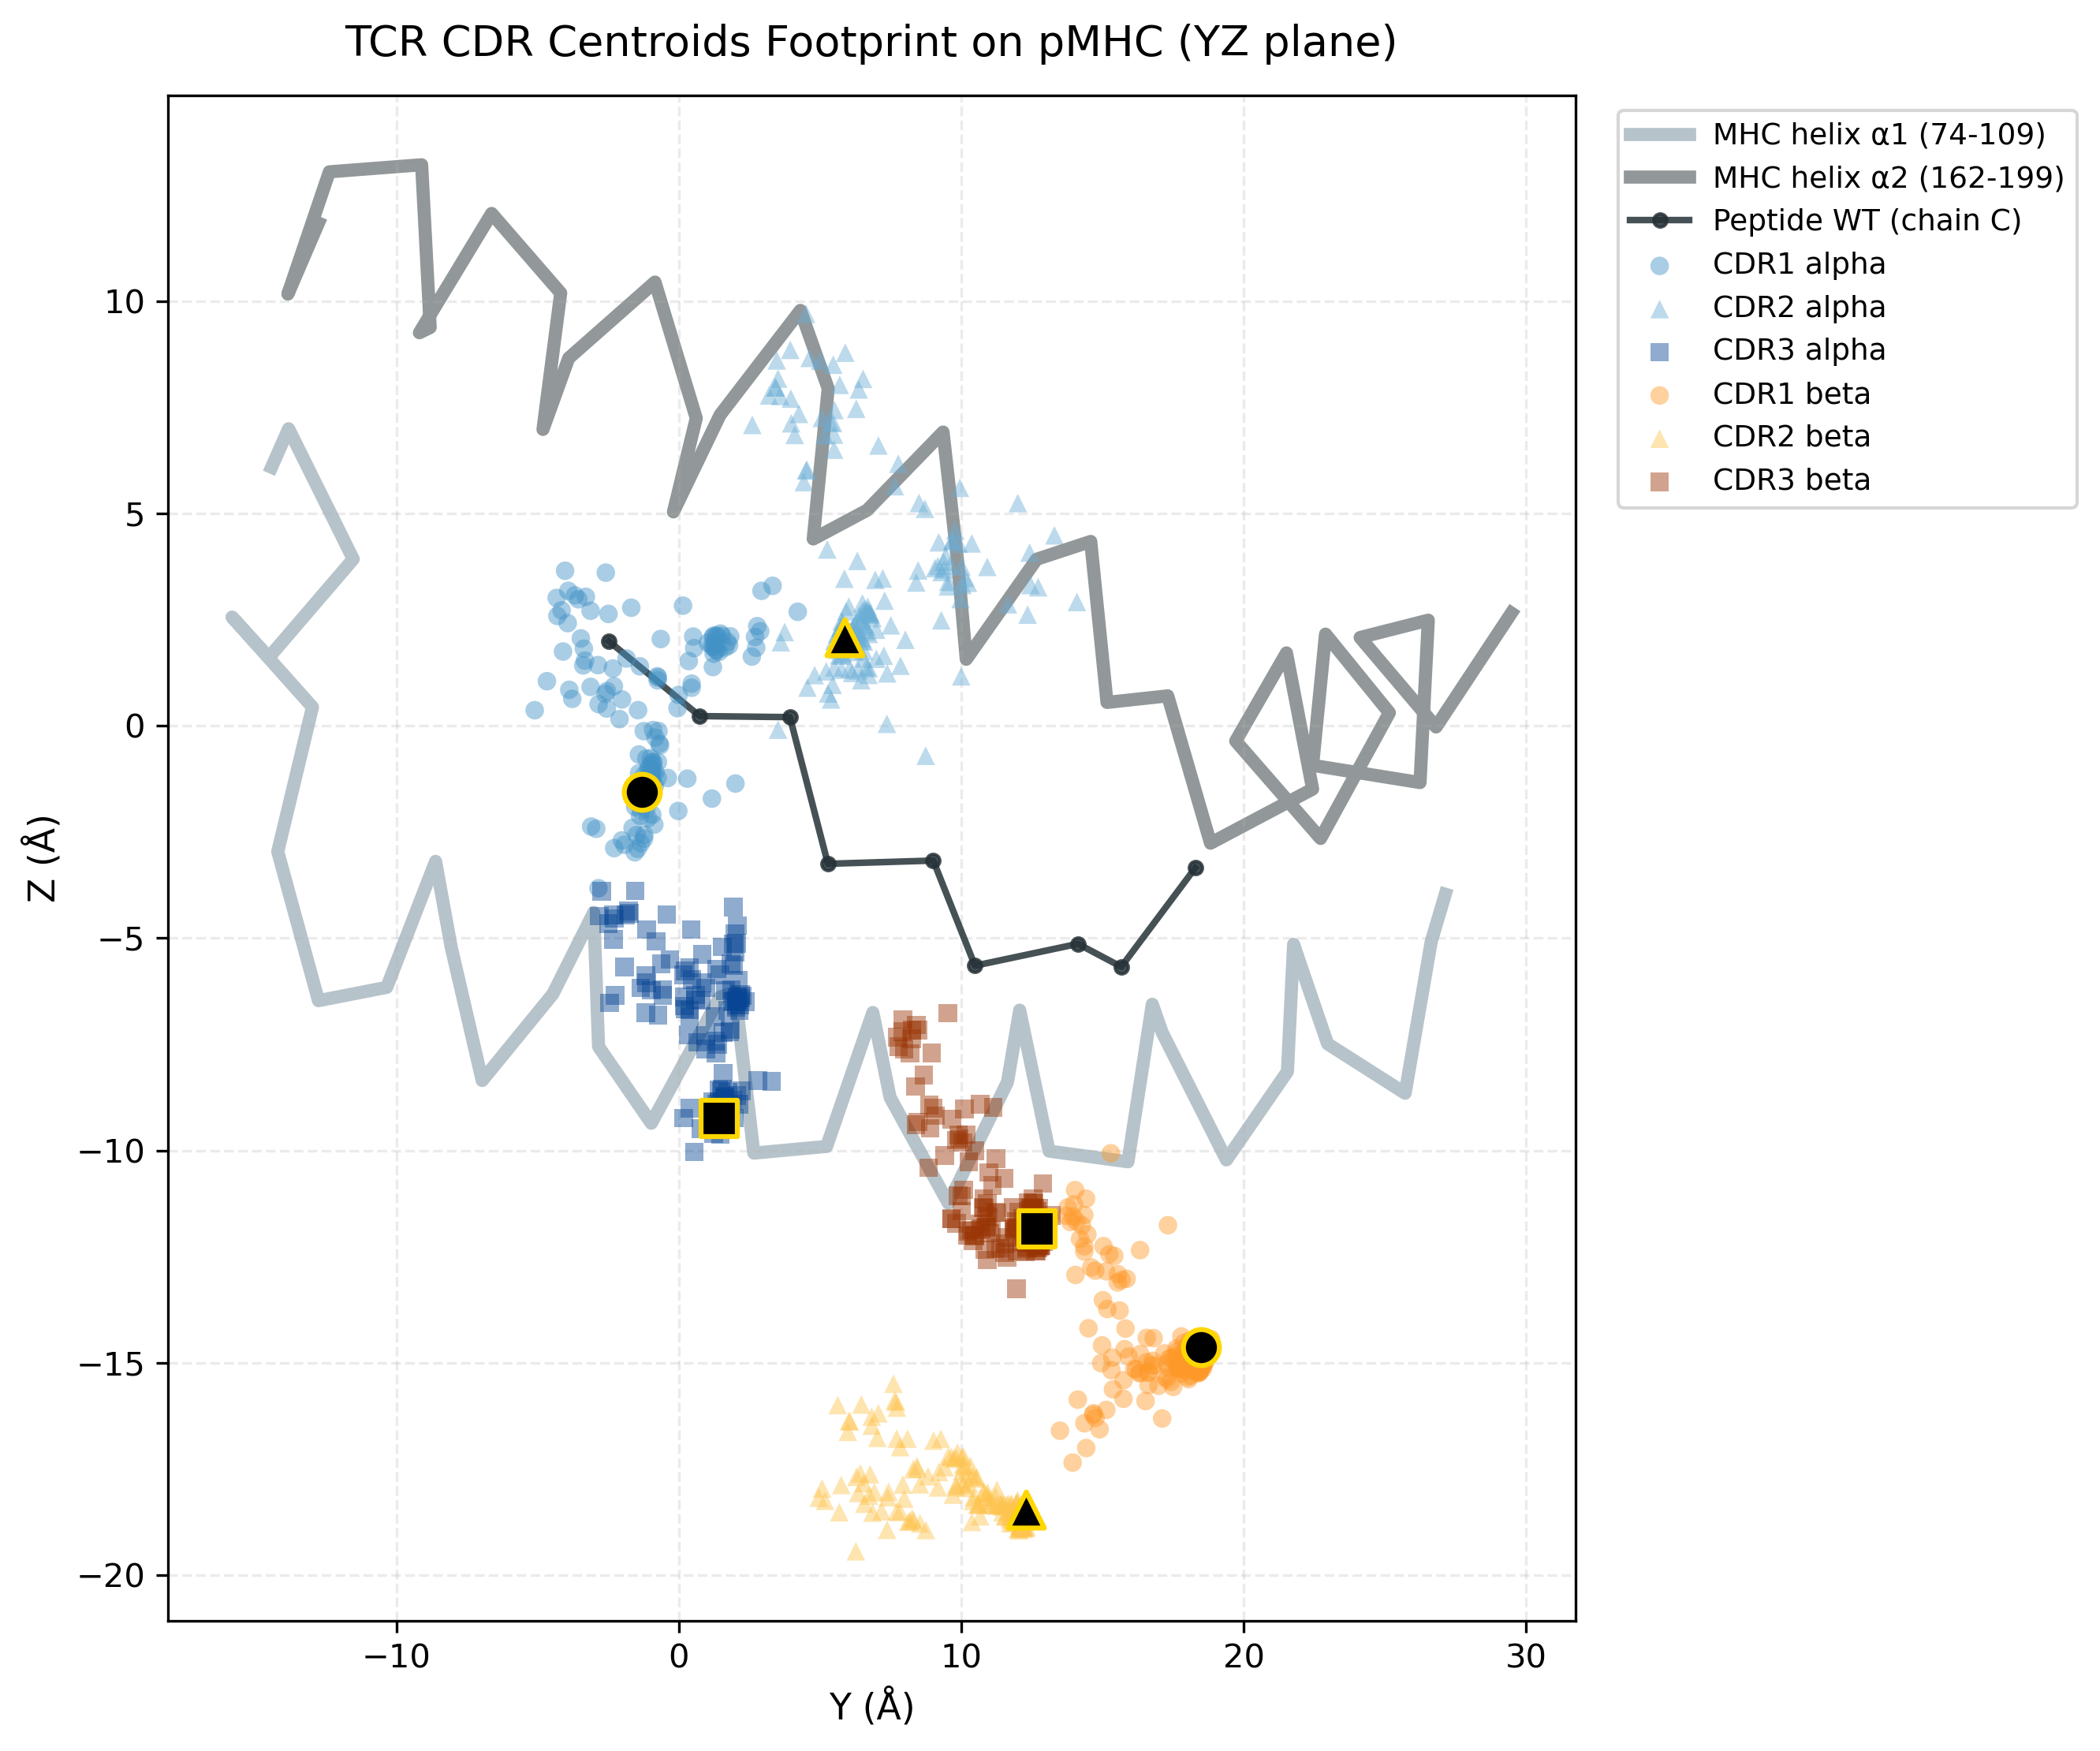

In [8]:
h1 = df_mhc[df_mhc["feature"] == "mhc_helix1"]
h2 = df_mhc[df_mhc["feature"] == "mhc_helix2"]
pep = df_mhc[df_mhc["feature"] == "peptide"]

colors = {
    "CDR1_alpha": "#4292c6",  # Bleu clair
    "CDR2_alpha": "#6baed6",  # Bleu ciel
    "CDR3_alpha": "#084594",  # Bleu marine foncé
    "CDR1_beta":  "#fe9929",  # Orange clair
    "CDR2_beta":  "#fec44f",  # Jaune orangé
    "CDR3_beta":  "#993404",  # Orange brique foncé
}

markers = {
    "CDR1_alpha": "o", "CDR2_alpha": "^", "CDR3_alpha": "s",
    "CDR1_beta":  "o", "CDR2_beta":  "^", "CDR3_beta":  "s"
}

planes = [("x", "y"), ("x", "z"), ("y", "z")]
mask_wt = df_com["is_wt"]
mask_mut = ~df_com["is_wt"]

for dim1, dim2 in planes:
    fig, ax = plt.subplots(figsize=(9, 7.5), dpi=300)

    ax.plot(
        h1[dim1], h1[dim2],
        color="#90a4ae", linewidth=4.0, alpha=0.65,
        linestyle="-", label="MHC helix α1 (74-109)", zorder=1
    )
    ax.plot(
        h2[dim1], h2[dim2],
        color="#586063", linewidth=4.0, alpha=0.65,
        linestyle="-", label="MHC helix α2 (162-199)", zorder=1
    )
    ax.plot(
        pep[dim1], pep[dim2],
        color="#263238", linewidth=2.0, marker="o", markersize=4,
        alpha=0.85, label="Peptide WT (chain C)", zorder=2
    )

    for cdr_name, col in colors.items():
        ax.scatter(
            df_com.loc[mask_mut, f"{cdr_name}_{dim1}"],
            df_com.loc[mask_mut, f"{cdr_name}_{dim2}"],
            color=col,
            marker=markers[cdr_name],
            alpha=0.45,
            s=32,
            edgecolors="none",
            label=cdr_name.replace("_", " "),
            zorder=3
        )

    if mask_wt.any():
        for cdr_name in colors.keys():
            ax.scatter(
                df_com.loc[mask_wt, f"{cdr_name}_{dim1}"],
                df_com.loc[mask_wt, f"{cdr_name}_{dim2}"],
                color="black",
                edgecolors="gold",
                linewidths=1.5,
                marker=markers[cdr_name],
                s=120,
                zorder=4
            )

    ax.set_title(f"TCR CDR Centroids Footprint on pMHC ({dim1.upper()}{dim2.upper()} plane)", fontsize=13, pad=12)
    ax.set_xlabel(f"{dim1.upper()} (Å)", fontsize=11)
    ax.set_ylabel(f"{dim2.upper()} (Å)", fontsize=11)
    

    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, fontsize=9)
    ax.grid(True, linestyle="--", alpha=0.25)
    
    plt.tight_layout()
    plot_filename = f"../figures/{pep_folder}/footprint_pMHC_{dim1.upper()}{dim2.upper()}.png"
    plt.savefig(plot_filename)
    plt.show()
    plt.close()